# LuxuryStay Hotel — Customer Segmentation & ML Notebook

**Author:** Oluwapelumi Alagbe

**Purpose:**
This notebook is a polished, presentation-ready pipeline that performs *customer-level segmentation* for LuxuryStay Hotel, builds a *cancellation prediction* model, and produces a *Customer Lifetime Value (CLTV)* model. It includes explanations, plots, and exports suitable for business stakeholders and portfolio/interview presentation.

---
> **How to use:**
> 1. Place your CSV file (e.g., `luxurystay_hotel_bookings.csv`) in the same folder.
> 2. Update the `DATA_PATH` variable in the first code cell if needed.
> 3. Run the notebook top-to-bottom. Cells are split for clarity (EDA, preprocessing, clustering, supervised models, CLTV).

---

## 1. Setup & Imports

In [2]:
# Cell 1 — Setup
import warnings
warnings.filterwarnings('ignore')

import hashlib
from datetime import timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

sns.set(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Config — update path if needed
DATA_PATH = 'luxurystay_hotel_bookings.csv'  # <-- change to your filename
OUTPUT_CUSTOMER_SEGMENTS = 'customer_segments.csv'
OUTPUT_CLUSTER_PROFILES = 'cluster_profiles.csv'
PLOT_DPI = 120

---

## 2. Load data and quick inspection

In [3]:
# Cell 2 — Load data
raw = pd.read_csv(DATA_PATH, dtype=str)
print('Raw shape:', raw.shape)
raw.head()

Raw shape: (10000, 36)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,City Hotel,0,155,2015,August,34,17,0,4,2,...,Transient,112.02,2,0,Check-Out,2015-08-21,Allison Hill,donaldgarcia@example.net,+1-219-560-0133,5111
1,City Hotel,0,29,2015,February,8,21,2,2,1,...,Transient,118.24,0,0,Check-Out,2015-02-25,Ian Cooper,lindsay78@example.org,(518)349-5931x0341,8321
2,City Hotel,0,16,2016,July,28,17,1,0,2,...,Transient,184.86,0,2,Check-Out,2016-07-18,Devin Schaefer,gabriellecameron@example.org,505.964.1395,6532
3,City Hotel,0,27,2016,May,20,16,0,1,2,...,Transient,144.22,1,1,Check-Out,2016-05-17,Brenda Snyder PhD,hernandezernest@example.net,(791)366-9784x80184,9322
4,City Hotel,0,41,2016,April,13,2,0,1,2,...,Transient,243.73,1,0,Check-Out,2016-04-03,Christopher Ashley,georgetracy@example.org,(443)903-9117x182,8718


**Markdown:** The dataset should contain booking-level records. We'll perform privacy steps (hash PII) then aggregate bookings into customer profiles.

---

## 3. Privacy-preserving customer id, basic cleaning & type conversions

In [4]:
# Cell 3 — Basic conversions & create customer id

def make_customer_id(row):
    pick = row.get('email')
    if pd.isna(pick) or str(pick).strip() == '':
        pick = f"{row.get('name','')}-{row.get('phone-number','')}"
    pick = str(pick).strip().lower()
    return hashlib.sha256(pick.encode('utf-8')).hexdigest()[:16]

# create copy
df = raw.copy()

# Convert numeric-like columns to numeric types where present
numeric_cols_guess = [
    'lead_time','arrival_date_year','arrival_date_week_number','arrival_date_day_of_month',
    'stays_in_weekend_nights','stays_in_week_nights','adults','children','babies',
    'is_repeated_guest','previous_cancellations','previous_bookings_not_canceled',
    'booking_changes','days_in_waiting_list','adr','required_car_parking_spaces',
    'total_of_special_requests','is_canceled'
]
for c in numeric_cols_guess:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

# parse reservation_status_date and arrival_date when possible
if 'reservation_status_date' in df.columns:
    df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'], errors='coerce')

# create arrival_date if year/month/day exist
if {'arrival_date_year','arrival_date_month','arrival_date_day_of_month'}.issubset(df.columns):
    def month_to_num(m):
        try:
            return pd.to_datetime(m, format='%B').month
        except:
            try:
                return int(m)
            except:
                return np.nan
    df['arrival_month_num'] = df['arrival_date_month'].apply(month_to_num)
    df['arrival_date'] = pd.to_datetime(
        df['arrival_date_year'].fillna(1900).astype(int).astype(str) + '-' +
        df['arrival_month_num'].fillna(1).astype(int).astype(str) + '-' +
        df['arrival_date_day_of_month'].fillna(1).astype(int).astype(str), errors='coerce',
    )

# create customer_id
if ('email' in df.columns) or ('name' in df.columns) or ('phone-number' in df.columns):
    df['customer_id'] = df.apply(make_customer_id, axis=1)
else:
    # fallback: create artificial id from index
    df['customer_id'] = df.index.astype(str)

# drop PII columns for the working dataset
pii_cols = [c for c in ['name','email','phone-number','credit_card'] if c in df.columns]
if pii_cols:
    df.drop(columns=pii_cols, inplace=True)

print('After basic cleaning:', df.shape)

After basic cleaning: (10000, 35)


---

## 4. Row-level feature engineering (booking-level)

Explain: create booking-level features like `total_nights`, `total_guests`, `revenue`, `guest_type`, `season`.

In [5]:
# Cell 4 — booking-level features
# Fill numeric small-missing values and compute derived columns
for c in ['children','babies','adults']:
    if c in df.columns:
        df[c] = df[c].fillna(0).astype(float)

# zero-fill booking counts
for c in ['previous_cancellations','previous_bookings_not_canceled','booking_changes',
          'days_in_waiting_list','stays_in_weekend_nights','stays_in_week_nights','total_of_special_requests']:
    if c in df.columns:
        df[c] = df[c].fillna(0).astype(float)

# adr median impute
if 'adr' in df.columns:
    df['adr'] = pd.to_numeric(df['adr'], errors='coerce')
    df['adr'] = df['adr'].fillna(df['adr'].median())

# total nights, guests, revenue
if 'stays_in_weekend_nights' in df.columns and 'stays_in_week_nights' in df.columns:
    df['total_nights'] = df['stays_in_weekend_nights'].fillna(0) + df['stays_in_week_nights'].fillna(0)
else:
    df['total_nights'] = 0

if all(c in df.columns for c in ['adults','children','babies']):
    df['total_guests'] = df['adults'].fillna(0) + df['children'].fillna(0) + df['babies'].fillna(0)
else:
    df['total_guests'] = df['adults'].fillna(0)

# revenue
if 'adr' in df.columns:
    df['revenue'] = df['adr'] * df['total_nights']
else:
    df['revenue'] = 0

# simple guest type
def guest_type_row(r):
    tg = r['total_guests']
    ch = r.get('children', 0)
    if tg <= 1:
        return "Single"
    if tg == 2 and ch == 0:
        return "Couple"
    if ch > 0:
        return "Family"
    return "Group"

if 'total_guests' in df.columns:
    df['guest_type'] = df.apply(guest_type_row, axis=1)

# arrival_month and season
if 'arrival_date' in df.columns and df['arrival_date'].notnull().any():
    df['arrival_month'] = df['arrival_date'].dt.month
else:
    if 'arrival_date_month' in df.columns:
        df['arrival_month'] = pd.to_datetime(df['arrival_date_month'], format='%B', errors='coerce').dt.month
    else:
        df['arrival_month'] = np.nan

def season_from_month(m):
    if pd.isna(m):
        return 'Unknown'
    m = int(m)
    if m in [12,1,2]: return 'Winter'
    if m in [3,4,5]: return 'Spring'
    if m in [6,7,8]: return 'Summer'
    return 'Autumn'

if 'arrival_month' in df.columns:
    df['season'] = df['arrival_month'].apply(season_from_month)

print('Booking-level features created. Sample:')
df[['customer_id','total_nights','total_guests','revenue','guest_type','season']].head()

Booking-level features created. Sample:


,customer_id,total_nights,total_guests,revenue,guest_type,season
0,6784ef8067c2e78b,4.0,2.0,448.08,Couple,Summer
1,3543b016783a36b6,4.0,1.0,472.96,Single,Winter
2,f5a33665c4c7c420,1.0,2.0,184.86,Couple,Summer
3,0352b4e4501ac57b,1.0,2.0,144.22,Couple,Spring
4,71b2c8c1a2876147,1.0,2.0,243.73,Couple,Spring


---

## 5. Aggregate bookings into customer-level profiles (RFM + behavioral features)

Explain: We aggregate earlier bookings up to a cutoff date and create recency, frequency, monetary features. We'll also compute additional behavioral stats.

In [6]:
# Cell 5 — aggregation to customer-level
# choose a date reference (max known reservation date)
if 'reservation_status_date' in df.columns and df['reservation_status_date'].notnull().any():
    date_ref = df['reservation_status_date'].max()
elif 'arrival_date' in df.columns and df['arrival_date'].notnull().any():
    date_ref = df['arrival_date'].max()
else:
    date_ref = pd.Timestamp.today()
print('Date reference for recency:', date_ref.date())

grouped = df.groupby('customer_id')

# numeric aggregations
agg_num = {
    'revenue': ['sum','mean','median'],
    'adr': ['mean','median'],
    'total_nights': ['sum','mean','median'],
    'total_guests': ['mean'],
    'lead_time': ['mean','median'],
    'is_canceled': ['mean'],
    'previous_cancellations': ['sum'],
    'previous_bookings_not_canceled': ['sum'],
    'booking_changes': ['mean'],
    'total_of_special_requests': ['mean']
}
agg_num = {k:v for k,v in agg_num.items() if k in df.columns}

cust = grouped.agg(agg_num)
# flatten columns
cust.columns = ['_'.join(col).strip() for col in cust.columns.values]

# add counts and dates
cust['total_bookings'] = grouped.size()
if 'reservation_status_date' in df.columns:
    cust_dates = grouped['reservation_status_date'].agg(['min','max']).rename(columns={'min':'first_booking_date','max':'last_booking_date'})
elif 'arrival_date' in df.columns:
    cust_dates = grouped['arrival_date'].agg(['min','max']).rename(columns={'min':'first_booking_date','max':'last_booking_date'})
else:
    cust_dates = None

if cust_dates is not None:
    cust = cust.join(cust_dates)
    cust['recency_days'] = (date_ref - cust['last_booking_date']).dt.days
    cust['active_days'] = (cust['last_booking_date'] - cust['first_booking_date']).dt.days.replace(0, np.nan)
    cust['booking_freq_per_day'] = cust['total_bookings'] / cust['active_days']
else:
    cust['recency_days'] = np.nan
    cust['booking_freq_per_day'] = np.nan

# add modes for categorical booking-level columns
categorical_cols_for_mode = [
    'country',
    'market_segment',
    'distribution_channel',
    'customer_type',
    'deposit_type',
    'guest_type',
    'season',
    'reserved_room_type',
    'assigned_room_type',
]

categorical_cols_for_mode = [c for c in categorical_cols_for_mode if c in df.columns]

modes = {}
for c in categorical_cols_for_mode:
    modes[c] = grouped[c].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)

if modes:
    cust = cust.join(pd.DataFrame(modes))

cust = cust.reset_index()
print('Customer-level shape:', cust.shape)
print(cust.head().T)

Date reference for recency: 2018-01-18
Customer-level shape: (9797, 32)
                                                      0                    1  \
customer_id                            000291c0bd90de05     0005dfb121445b53   
revenue_sum                                      237.99              2852.43   
revenue_mean                                     237.99              2852.43   
revenue_median                                   237.99              2852.43   
adr_mean                                          79.33               135.83   
adr_median                                        79.33               135.83   
total_nights_sum                                    3.0                 21.0   
total_nights_mean                                   3.0                 21.0   
total_nights_median                                 3.0                 21.0   
total_guests_mean                                   1.0                  1.0   
lead_time_mean                                  

---

## 6. Prepare features for clustering (impute, scale, encode)

Explain: we will frequency-encode categorical modes (keeps dimensionality low), impute numeric medians, scale, then run PCA for visualization.

Clustering features count: 19


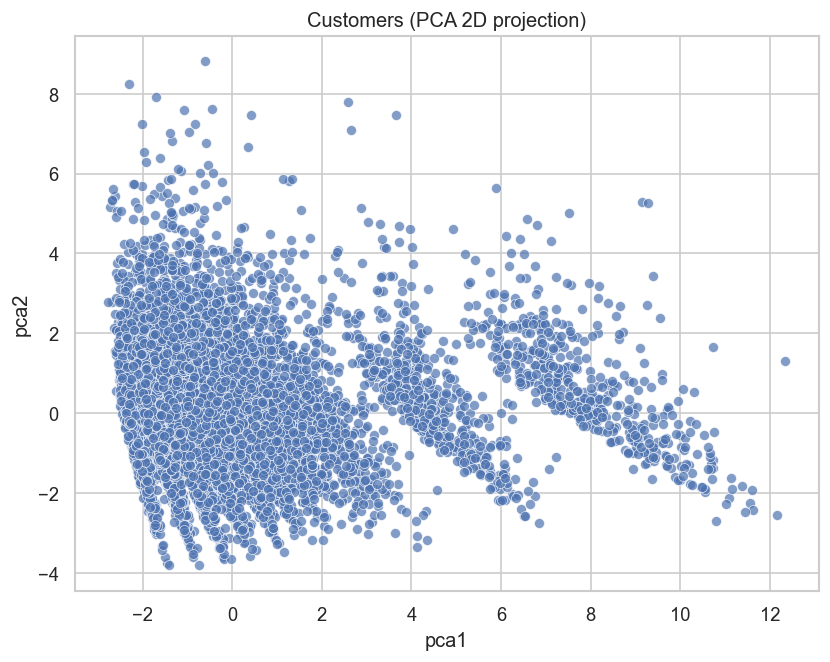

In [7]:
# Cell 6 — feature prep
# select numeric features
numeric_features = [c for c in cust.columns if any(suf in c for suf in ['_sum','_mean','_median','total_bookings','recency_days','booking_freq_per_day'])]
# remove date columns
numeric_features = [c for c in numeric_features if 'date' not in c]

# frequency encode categorical modes
from collections import defaultdict
freq_maps = defaultdict(dict)
for c in categorical_cols_for_mode:
    mode_col = c+'_mode'
    if mode_col in cust.columns:
        cust[mode_col] = cust[mode_col].fillna('Missing').astype(str)
        freqs = cust[mode_col].value_counts(normalize=True).to_dict()
        cust[mode_col+'_freq'] = cust[mode_col].map(freqs)
        freq_maps[c] = freqs

cat_freq_cols = [c for c in cust.columns if c.endswith('_freq')]

# build final feature list
features = numeric_features + cat_freq_cols
print('Clustering features count:', len(features))

# impute and scale
imp = SimpleImputer(strategy='median')
Xnum = imp.fit_transform(cust[features])
scaler = StandardScaler()
Xscaled = scaler.fit_transform(Xnum)

# PCA 2D for visualization
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca2 = pca2.fit_transform(Xscaled)
cust['pca1'] = X_pca2[:,0]
cust['pca2'] = X_pca2[:,1]

plt.figure(figsize=(8,6), dpi=PLOT_DPI)
sns.scatterplot(x='pca1', y='pca2', data=cust, alpha=0.7)
plt.title('Customers (PCA 2D projection)')
plt.show()

---

## 7. Clustering: choose k (silhouette) and profile clusters

k=2, silhouette=0.4199
k=3, silhouette=0.1542
k=4, silhouette=0.1609
k=5, silhouette=0.1722
k=6, silhouette=0.1783
k=7, silhouette=0.1874
k=8, silhouette=0.1954
Best k by silhouette: 2


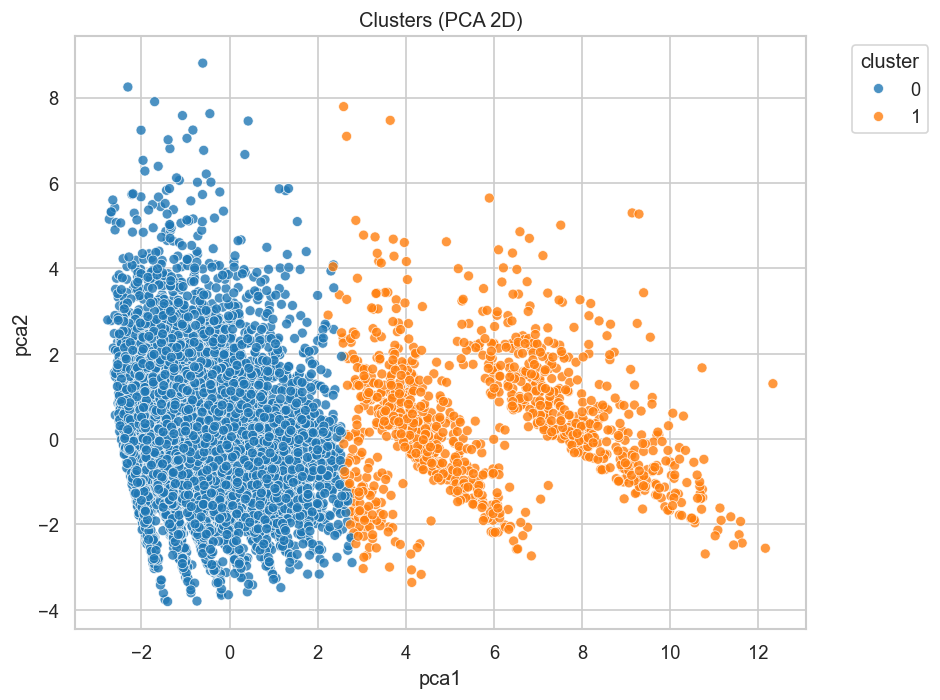

Saved customer_segments.csv and cluster_profiles.csv


In [8]:
# Cell 7 — choose k
scores = {}
K_range = range(2,9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(Xscaled)
    scores[k] = silhouette_score(Xscaled, labels)
    print(f'k={k}, silhouette={scores[k]:.4f}')

best_k = max(scores, key=scores.get)
print('Best k by silhouette:', best_k)

# fit final
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=50)
cust['cluster'] = kmeans.fit_predict(Xscaled)

# visualize clusters
plt.figure(figsize=(8,6), dpi=PLOT_DPI)
sns.scatterplot(x='pca1', y='pca2', hue='cluster', palette='tab10', data=cust, alpha=0.8)
plt.title('Clusters (PCA 2D)')
plt.legend(title='cluster', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

# profile clusters
cluster_profiles = []
for c in sorted(cust['cluster'].unique()):
    sub = cust[cust['cluster']==c]
    prof = {'cluster': c, 'size': len(sub), 'share': len(sub)/len(cust)}
    for nf in numeric_features:
        prof['median_'+nf] = sub[nf].median() if nf in sub.columns else np.nan
    for col in categorical_cols_for_mode:
        mode_col = col+'_mode'
        prof['top_'+col] = sub[mode_col].mode().iloc[0] if mode_col in sub.columns and not sub[mode_col].mode().empty else np.nan
    cluster_profiles.append(prof)

cluster_profiles = pd.DataFrame(cluster_profiles).sort_values('cluster')
cluster_profiles

# save outputs
cust.to_csv(OUTPUT_CUSTOMER_SEGMENTS, index=False)
cluster_profiles.to_csv(OUTPUT_CLUSTER_PROFILES, index=False)
print('Saved customer_segments.csv and cluster_profiles.csv')

---

## 8. Customer Lifetime Value (CLTV) modeling — approach & two methods

**Approach:** We'll provide two CLTV approaches:
1. *Heuristic CLTV proxy* — based on historical spend and recency/frequency (fast to compute and explainable) 
2. *Predictive CLTV* — supervised regression model predicting customer future revenue (requires holdout period and non-overlapping training/target windows)

### 9.1 Heuristic CLTV (RFM-based)

In [9]:
# Cell 9a — heuristic CLTV
# simple RFM: Recency (days), Frequency (total_bookings), Monetary (revenue_sum)
cust['R'] = cust['recency_days']
cust['F'] = cust['total_bookings']
cust['M'] = cust['revenue_sum'] if 'revenue_sum' in cust.columns else cust['revenue_mean']

# normalize each component to [0,1] (higher better for R invert because smaller recency => better)
from sklearn.preprocessing import MinMaxScaler
mms = MinMaxScaler()
rfm = cust[['R','F','M']].fillna(0).copy()
rfm['R'] = -rfm['R']  # invert recency: more recent => larger value
rfm_scaled = mms.fit_transform(rfm)

cust['cltv_rfm_score'] = (0.4*rfm_scaled[:,2]) + (0.3*rfm_scaled[:,1]) + (0.3*rfm_scaled[:,0])
# scale to estimated monetary range (optional): multiply by average yearly revenue
avg_year_rev = cust['revenue_sum'].mean() if 'revenue_sum' in cust.columns else cust['revenue_mean'].mean()
cust['cltv_rfm_estimate'] = cust['cltv_rfm_score'] * avg_year_rev * 1.0  # 1-year proxy

cust[['customer_id','cltv_rfm_estimate']].sort_values('cltv_rfm_estimate', ascending=False).head()

,customer_id,cltv_rfm_estimate
1313,23316a7751e90169,652.664801
3568,5cd438a4a0de35e5,631.114006
1994,347e2e2da98702cf,615.346455
751,13e963c7cbe6dfb1,614.362083
7476,c2d67faa64975c83,607.664649


### 9.2 Predictive CLTV (supervised)

**Design:** Define a cutoff date to split history vs future. For each customer, use historical features before cutoff to predict revenue in the following period (e.g., next 365 days). This requires sufficient date range.

In [11]:
# Cell 9b — predictive CLTV
# determine cutoff date: leave-last-year as holdout (if data spans multiple years)
if 'reservation_status_date' in df.columns and df['reservation_status_date'].notnull().any():
    overall_max_date = df['reservation_status_date'].max()
elif 'arrival_date' in df.columns and df['arrival_date'].notnull().any():
    overall_max_date = df['arrival_date'].max()
else:
    overall_max_date = pd.Timestamp.today()

cutoff = overall_max_date - pd.Timedelta(days=365)  # one-year holdout
print('Cutoff for train/history:', cutoff.date())

# historical and future splits at booking level
hist = df[df['reservation_status_date'] <= cutoff] if 'reservation_status_date' in df.columns else df[df['arrival_date'] <= cutoff]
future = df[df['reservation_status_date'] > cutoff] if 'reservation_status_date' in df.columns else df[df['arrival_date'] > cutoff]

# compute target: revenue in future period per customer
future_rev = future.groupby('customer_id')['revenue'].sum().rename('future_revenue')

# compute historical features per customer (reuse cust aggregated earlier but recompute on hist)
hist_grouped = hist.groupby('customer_id')

hist_agg = hist_grouped.agg({
    'revenue': ['sum','mean'],
    'total_nights': ['sum','mean'],
    'lead_time': ['mean'],
    'is_canceled': ['mean'],
    'total_of_special_requests': ['mean']
})
hist_agg.columns = ['_'.join(c) for c in hist_agg.columns]
hist_agg['total_bookings_hist'] = hist_grouped.size()

# merge with target
cltv_df = hist_agg.merge(future_rev, left_index=True, right_index=True, how='left').fillna(0)
print('Predictive CLTV dataset shape:', cltv_df.shape)

# features and target
cltv_X = cltv_df.drop(columns=['future_revenue'])
cltv_y = cltv_df['future_revenue']

# train/test split
X_train, X_test, y_train, y_test = train_test_split(cltv_X, cltv_y, test_size=0.25, random_state=RANDOM_STATE)

# model: gradient boosting regressor
gbr = GradientBoostingRegressor(n_estimators=200, random_state=RANDOM_STATE)
gbr.fit(X_train, y_train)

# evaluate
preds = gbr.predict(X_test)
from sklearn.metrics import mean_absolute_error, mean_squared_error
print('MAE:', mean_absolute_error(y_test, preds))
print('RMSE (sqrt):', np.sqrt(mean_squared_error(y_test, preds)))

# feature importances
feat_imp = pd.Series(gbr.feature_importances_, index=cltv_X.columns).sort_values(ascending=False)
print('Top predictive features for CLTV:')
print(feat_imp.head(10))

# attach predicted CLTV back to cust dataframe for business use
pred_all = pd.Series(gbr.predict(cltv_X), index=cltv_X.index, name='predicted_future_revenue')
cltv_df = cltv_df.join(pred_all)
cltv_df.reset_index(inplace=True)
cltv_df[['customer_id','predicted_future_revenue']].sort_values('predicted_future_revenue', ascending=False).head()

Cutoff for train/history: 2017-01-18
Predictive CLTV dataset shape: (6690, 9)
MAE: 28.64273635621123
RMSE (sqrt): 197.54260372406506
Top predictive features for CLTV:
revenue_mean                      0.446249
revenue_sum                       0.435784
lead_time_mean                    0.057790
total_nights_sum                  0.018952
total_nights_mean                 0.012515
total_of_special_requests_mean    0.012351
is_canceled_mean                  0.008200
total_bookings_hist               0.008159
dtype: float64


,customer_id,predicted_future_revenue
2848,6c92435cc1048dfd,1610.656833
1448,383d76e8f203e4ec,1409.250770
4323,a4769070fbdb80a7,1151.765343
2060,4fa99be0e839fc87,1075.301073
865,224c4f4dad71f2ef,1001.776152


---

## 10. Presentation & Export

In [12]:
# Cell 10 — save outputs and generate a small summary table
cust_profiles_export = cust.copy()
# merge predicted CLTV where available
cust_profiles_export = cust_profiles_export.merge(cltv_df[['customer_id','predicted_future_revenue']], on='customer_id', how='left')

cust_profiles_export.to_csv('customer_profiles_full.csv', index=False)
cluster_profiles.to_csv('cluster_profiles.csv', index=False)
print('Saved: customer_profiles_full.csv and cluster_profiles.csv')

Saved: customer_profiles_full.csv and cluster_profiles.csv


**Markdown:** At this point you have:
- `customer_profiles_full.csv` — customer-level features, cluster labels, PCA coords
- `cluster_profiles.csv` — summarized cluster KPIs
- `customer_segments.csv` — if you saved earlier
- CLTV model outputs: `predicted_future_revenue` for each customer (where applicable)

---

## 11. Interpretation tips & next steps (for slides)

**Suggested slide flow for a presentation:**
1. Project aim & data summary (rows, fields, time window)
2. Data quality & privacy (how `customer_id` was created and PII removed)
3. Customer-level segmentation — method (features, clustering algorithm, chosen k) and visualization (PCA scatter, cluster profiles table)
4. Business recommendations per cluster (example: "Cluster 0 — High-value long-stayers: concierge upsell, premium offers")
5. Cancellation model results and operational actions (targeted reminders, flexible deposits)
6. CLTV approach & top predicted customers for loyalty offers
7. Next steps & assumptions (add in-stay spend, loyalty program data, A/B test targeting)

---

### End of notebook — you can now run cell-by-cell in Jupyter, tweak parameters, and export to HTML/Slides for presentation.